# SI3007 — Análisis Descriptivo de Calidad del Aire, Clima y Población (EE. UU., 2024)

## 1. Propósito y Arquitectura
Este cuaderno ejecuta el procesamiento analítico descriptivo del proyecto sobre un clúster **Amazon EMR** con **Apache Spark (PySpark y SparkSQL)**.

* **¿Qué se hace?** Se leen los **323,540 registros integrados** de 2024 (EPA AQI diario + NOAA clima diario + Census 2024) directamente desde la zona **Trusted** en Amazon S3 a través del **AWS Glue Data Catalog** (`airquality_trusted.aqi_weather`), se audita su calidad, se responden las preguntas guía y se publican los resultados agregados en la zona **Refined (Gold)** (`s3://.../refined/` en Parquet y JSON).
* **¿Por qué así?** Usar **Spark distribuido en memoria** permite calcular agregaciones, cuantiles y funciones de ventana (*Window functions*) sobre cientos de miles de registros sin descargar datos crudos a una sola máquina, y desacopla el cómputo analítico de la capa de consumo (**AWS Lambda + API Gateway + Streamlit**).

---

## 2. Preguntas de Negocio y Metodología
El análisis cubre los estados continentales/monitoreados de EE. UU. en 2024 (`state_code <= '56'`), aplicando reglas explícitas de cobertura y reportando tamaños de muestra y exclusiones:

| Pregunta | Qué responde | Cómo se calcula en PySpark / SparkSQL |
| :--- | :--- | :--- |
| **P1** | Ranking geográfico de condados y estados con mayor AQI promedio. | Filtra condados elegibles ($\ge 180$ días válidos y $\ge 6$ meses con $\ge 15$ días). Calcula promedios por condado y promedio estatal con **igual peso por condado**, reportando cobertura y población. |
| **P2** | Meses con mayores concentraciones promedio en 2024. | Construye un **panel balanceado** (los mismos condados con $\ge 75\%$ de días válidos en los 12 meses) para evitar sesgos estacionales; calcula media, mediana, rango intercuartílico (`P25–P75`) y temperatura media. |
| **P3** | Diferencias entre días laborales (Lun–Vie) y fines de semana (Sáb–Dom). | Contraste pareado $(\text{Fin de semana} - \text{Laboral})$ dentro de cada `condado-mes` con $\ge 4$ días válidos en cada grupo, resumiendo media, mediana y desviación mensual. |
| **P4\*** | Comportamiento del AQI frente a condiciones climáticas diarias *(adaptada de granularidad horaria a diaria)*. | Clasifica los días en 4 rangos de temperatura máxima (`tmax_c`) cruzados con condición seca vs. lluvia (`precipitation_mm > 0`) mediante SparkSQL, y estima correlaciones globales por contaminante. |
| **P5** | Condados con mayor porcentaje de días con `AQI > 100`. | Calcula $100 \times \frac{\text{días } AQI > 100}{\text{días válidos}}$ sobre condados con $\ge 180$ días válidos, desglosando episodios por `Ozone` vs. `PM2.5` y estimando **persona-días expuestos** con Census 2024. |
| **P6** | Asociación estadística descriptiva entre clima (`tmax_c`, `prcp`) y `AQI` por condado. | Exige $\ge 30$ pares válidos con varianza positiva por condado; calcula **Pearson** (`F.corr`) y **Spearman** mediante rangos medios con funciones de ventana (`Window`). |

---

## 3. Sobre el Tablero Final (Visualización 2×2)
Al cierre del notebook se presenta un tablero ejecutivo de cuatro cuadrantes generado en `matplotlib` consumiendo directamente los endpoints de la zona **Refined** vía **API Gateway**:
1. **Superior izquierdo (P1):** Barras horizontales con los 10 condados de mayor AQI promedio diario.
2. **Superior derecho (P2):** Curva mensual del panel balanceado con su **banda intercuartílica (P25–P75)**, evidenciando el pico de verano (julio).
3. **Inferior izquierdo (P3):** Barras de la diferencia mensual `Fin de semana − Laboral` con línea de referencia en cero (verde: menor en fin de semana; naranja: mayor).
4. **Inferior derecho (P5):** Ranking de los 10 condados con mayor proporción de días insalubres (`AQI > 100`).

In [1]:
import json
from pyspark.sql import functions as F, Window

BUCKET = "si3007-airquality-490445290869-lake"
TRUSTED_TABLE = "airquality_trusted.aqi_weather"
TRUSTED_S3_PATH = f"s3://{BUCKET}/trusted/aqi_weather"
REFINED_PARQUET_ROOT = f"s3://{BUCKET}/refined/parquet"
REFINED_JSON_ROOT = f"s3://{BUCKET}/refined/json"

try:
    raw_df = spark.table(TRUSTED_TABLE)
    source_mode = f"Glue Data Catalog ({TRUSTED_TABLE})"
except Exception:
    raw_df = spark.read.parquet(TRUSTED_S3_PATH)
    source_mode = f"S3 Parquet directo ({TRUSTED_S3_PATH})"

# Filtramos 2024 y los 50 estados + Distrito de Columbia (state_code <= '56')
df = (
    raw_df
    .withColumn("year_num", F.col("year").cast("int"))
    .withColumn("month_num", F.col("month").cast("int"))
    .filter((F.col("year_num") == 2024) & (F.col("state_code") <= "56"))
    .withColumn("aqi_d", F.col("aqi").cast("double"))
    .withColumn("tmax_d", F.col("tmax_c").cast("double"))
    .withColumn("tmin_d", F.col("tmin_c").cast("double"))
    .withColumn("tavg_d", F.col("tavg_c").cast("double"))
    .withColumn("prcp_d", F.col("precipitation_mm").cast("double"))
    .withColumn("pop_d", F.col("population_estimate").cast("double"))
    .withColumn("temp_range_c", F.col("tmax_d") - F.col("tmin_d"))
    .cache()
)

df.createOrReplaceTempView("aqi_weather")

total_rows = df.count()  # Acción que materializa el caché en los Executors
print(f"Fuente activa : {source_mode}")
print(f"Versión Spark : {spark.version}")
print(f"Filas en RAM  : {total_rows:,}")
df.printSchema()

Starting Spark application


ID,YARN Application ID,Kind,State,Spark UI,Driver log,User,Current session?
0,application_1795090213820_0001,pyspark,idle,Link,Link,None,✔


FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

SparkSession available as 'spark'.


FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

Fuente activa : Glue Data Catalog (airquality_trusted.aqi_weather)
Versi?n Spark : 3.4.1-amzn-2
Filas en RAM  : 323,540
root
 |-- state_name: string (nullable = true)
 |-- county_name: string (nullable = true)
 |-- state_code: string (nullable = true)
 |-- county_code: string (nullable = true)
 |-- measurement_date: date (nullable = true)
 |-- aqi: integer (nullable = true)
 |-- category: string (nullable = true)
 |-- defining_parameter: string (nullable = true)
 |-- defining_site: string (nullable = true)
 |-- sites_reporting: integer (nullable = true)
 |-- fips: string (nullable = true)
 |-- tmax_c: decimal(6,2) (nullable = true)
 |-- tmin_c: decimal(6,2) (nullable = true)
 |-- tavg_c: decimal(6,2) (nullable = true)
 |-- precipitation_mm: decimal(8,2) (nullable = true)
 |-- population_estimate: long (nullable = true)
 |-- year: string (nullable = true)
 |-- month: string (nullable = true)
 |-- year_num: integer (nullable = true)
 |-- month_num: integer (nullable = true)
 |-- aqi_d: d

In [2]:
# 1. KPIs globales del dataset integrado (SparkSQL)
kpis_df = spark.sql("""
    SELECT
        COUNT(*)                                                                  AS total_observations,
        COUNT(DISTINCT state_code)                                                AS states_and_dc,
        COUNT(DISTINCT fips)                                                      AS monitored_counties,
        CAST(MIN(measurement_date) AS STRING)                                     AS date_min,
        CAST(MAX(measurement_date) AS STRING)                                     AS date_max,
        COUNT(DISTINCT measurement_date)                                          AS distinct_dates,
        ROUND(AVG(aqi_d), 2)                                                      AS mean_aqi,
        ROUND(PERCENTILE_APPROX(aqi_d, 0.50), 2)                                  AS median_aqi,
        MAX(aqi)                                                                  AS max_aqi,
        SUM(CASE WHEN aqi > 100 THEN 1 ELSE 0 END)                                AS days_aqi_gt_100,
        ROUND(100.0 * SUM(CASE WHEN aqi > 100 THEN 1 ELSE 0 END) / COUNT(*), 2)   AS pct_days_aqi_gt_100,
        ROUND(100.0 * SUM(CASE WHEN defining_parameter = 'Ozone' THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_ozone_defining,
        ROUND(AVG(tavg_d), 2)                                                     AS mean_tavg_c,
        ROUND(AVG(prcp_d), 2)                                                     AS mean_prcp_mm,
        ROUND(100.0 * SUM(CASE WHEN population_estimate IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 2) AS census_coverage_pct
    FROM aqi_weather
""")
kpis_df.show(truncate=False, vertical=True)

# 2. Auditoría de nulos por columna
null_exprs = [
    F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(c)
    for c in ["state_name", "county_name", "measurement_date", "aqi", "category",
              "defining_parameter", "tmax_c", "tmin_c", "tavg_c", "precipitation_mm", "population_estimate"]
]
print("Conteo de valores nulos por columna:")
df.select(null_exprs).show(truncate=False, vertical=True)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

-RECORD 0-------------------------
 total_observations  | 323540     
 states_and_dc       | 48         
 monitored_counties  | 975        
 date_min            | 2024-01-01 
 date_max            | 2024-12-31 
 distinct_dates      | 366        
 mean_aqi            | 41.96      
 median_aqi          | 40.0       
 max_aqi             | 1513       
 days_aqi_gt_100     | 3911       
 pct_days_aqi_gt_100 | 1.21       
 pct_ozone_defining  | 51.08      
 mean_tavg_c         | 13.99      
 mean_prcp_mm        | 2.74       
 census_coverage_pct | 99.20      

Conteo de valores nulos por columna:
-RECORD 0-------------------
 state_name          | 0    
 county_name         | 0    
 measurement_date    | 0    
 aqi                 | 0    
 category            | 0    
 defining_parameter  | 0    
 tmax_c              | 0    
 tmin_c              | 0    
 tavg_c              | 0    
 precipitation_mm    | 0    
 population_estimate | 2598

In [3]:
numeric_vars = [
    ("aqi_d", "AQI diario"),
    ("tmax_d", "Temp. máxima (°C)"),
    ("tmin_d", "Temp. mínima (°C)"),
    ("tavg_d", "Temp. promedio (°C)"),
    ("temp_range_c", "Amplitud térmica (°C)"),
    ("prcp_d", "Precipitación (mm)"),
    ("pop_d", "Población condado (2024)")
]

summary_rows = []
for col_name, label in numeric_vars:
    row = df.select(
        F.lit(label).alias("variable"),
        F.count(col_name).alias("n_valid"),
        F.round(F.avg(col_name), 2).alias("mean"),
        F.round(F.stddev_samp(col_name), 2).alias("std"),
        F.round(F.min(col_name), 2).alias("min"),
        F.round(F.percentile_approx(col_name, 0.05), 2).alias("p05"),
        F.round(F.percentile_approx(col_name, 0.25), 2).alias("p25"),
        F.round(F.percentile_approx(col_name, 0.50), 2).alias("median"),
        F.round(F.percentile_approx(col_name, 0.75), 2).alias("p75"),
        F.round(F.percentile_approx(col_name, 0.95), 2).alias("p95"),
        F.round(F.percentile_approx(col_name, 0.99), 2).alias("p99"),
        F.round(F.max(col_name), 2).alias("max"),
        F.round(F.skewness(col_name), 2).alias("skewness"),
        F.round(F.kurtosis(col_name), 2).alias("kurtosis"),
    )
    summary_rows.append(row)

univariate_df = summary_rows[0]
for r in summary_rows[1:]:
    univariate_df = univariate_df.unionByName(r)

print("=== Estadística descriptiva univariada (2024) ===")
univariate_df.show(truncate=False)

# Frecuencia por categoría oficial de AQI (EPA)
category_dist_df = spark.sql("""
    SELECT
        category,
        COUNT(*) AS observations,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS share_pct,
        MIN(aqi) AS min_aqi,
        MAX(aqi) AS max_aqi,
        ROUND(AVG(tmax_d), 2) AS avg_tmax_c
    FROM aqi_weather
    GROUP BY category
    ORDER BY min_aqi
""")
print("=== Distribución por categoría EPA de calidad del aire ===")
category_dist_df.show(truncate=False)

# Frecuencia por contaminante definitorio (global y en episodios AQI > 100)
param_dist_df = spark.sql("""
    SELECT
        defining_parameter,
        COUNT(*) AS total_days,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS share_all_pct,
        ROUND(AVG(aqi_d), 2) AS avg_aqi,
        SUM(CASE WHEN aqi > 100 THEN 1 ELSE 0 END) AS days_gt_100,
        ROUND(100.0 * SUM(CASE WHEN aqi > 100 THEN 1 ELSE 0 END) /
              NULLIF(SUM(SUM(CASE WHEN aqi > 100 THEN 1 ELSE 0 END)) OVER (), 0), 2) AS share_gt_100_pct
    FROM aqi_weather
    GROUP BY defining_parameter
    ORDER BY total_days DESC
""")
print("=== Contaminante definitorio del AQI ===")
param_dist_df.show(truncate=False)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

=== Estad?stica descriptiva univariada (2024) ===
+------------------------+-------+---------+---------+------+------+-------+--------+--------+---------+---------+---------+--------+--------+
|variable                |n_valid|mean     |std      |min   |p05   |p25    |median  |p75     |p95      |p99      |max      |skewness|kurtosis|
+------------------------+-------+---------+---------+------+------+-------+--------+--------+---------+---------+---------+--------+--------+
|AQI diario              |323540 |41.96    |19.5     |0.0   |14.0  |31.0   |40.0    |51.0    |74.0     |105.0    |1513.0   |4.66    |197.85  |
|Temp. m?xima (?C)       |323540 |20.1     |10.57    |-30.5 |1.41  |12.44  |22.06   |28.43   |34.36    |37.47    |48.27    |-0.55   |-0.31   |
|Temp. m?nima (?C)       |323540 |7.88     |9.54     |-41.06|-7.81 |0.88   |8.23    |15.46   |22.4     |24.79    |32.76    |-0.33   |-0.25   |
|Temp. promedio (?C)     |323540 |13.99    |9.84     |-34.13|-2.77 |6.75   |15.22   |21.83  

In [4]:
monthly_cov = df.groupBy("state_code", "county_code", "month_num").agg(
    F.countDistinct("measurement_date").alias("days_in_month")
)

county_eligibility = (
    monthly_cov.groupBy("state_code", "county_code")
    .agg(
        F.sum("days_in_month").alias("valid_days"),
        F.sum(F.when(F.col("days_in_month") >= 15, 1).otherwise(0)).alias("months_15plus")
    )
    .withColumn("is_eligible_p1", (F.col("valid_days") >= 180) & (F.col("months_15plus") >= 6))
)

print("Auditoría de elegibilidad de condados (P1):")
county_eligibility.groupBy("is_eligible_p1").count().show()

eligible = county_eligibility.filter(F.col("is_eligible_p1")).select("state_code", "county_code", "valid_days")

# P1A: Ranking por condado
p1_counties_df = (
    df.join(eligible, ["state_code", "county_code"], "inner")
    .groupBy("state_name", "county_name", "fips", "valid_days")
    .agg(
        F.round(F.lit(100.0) * F.col("valid_days") / 366.0, 1).alias("coverage_pct_2024"),
        F.round(F.avg("aqi_d"), 2).alias("avg_aqi"),
        F.round(F.percentile_approx("aqi_d", 0.50), 2).alias("median_aqi"),
        F.round(F.stddev_samp("aqi_d"), 2).alias("sd_aqi"),
        F.round(F.avg(F.when(F.col("defining_parameter") == "Ozone", F.col("aqi_d"))), 2).alias("avg_aqi_ozone"),
        F.round(100.0 * F.sum(F.when(F.col("defining_parameter") == "Ozone", 1).otherwise(0)) / F.count("*"), 1).alias("pct_ozone"),
        F.max("population_estimate").alias("population_2024")
    )
    .orderBy(F.desc("avg_aqi"))
)

# P1B: Ranking por estado (igual peso por condado elegible)
p1_states_df = (
    p1_counties_df.groupBy("state_name")
    .agg(
        F.count("*").alias("eligible_counties"),
        F.when(F.count("*") == 1, "Un solo condado").otherwise("Múltiples condados").alias("coverage_note"),
        F.sum("valid_days").alias("total_county_days"),
        F.round(F.avg("avg_aqi"), 2).alias("state_avg_aqi"),
        F.round(F.min("avg_aqi"), 2).alias("min_county_aqi"),
        F.round(F.max("avg_aqi"), 2).alias("max_county_aqi"),
        F.sum("population_2024").alias("monitored_population_2024")
    )
    .orderBy(F.desc("state_avg_aqi"))
)

print("=== P1A: Top 15 condados por AQI promedio ===")
p1_counties_df.show(15, truncate=False)
print("=== P1B: Top 15 estados (igual peso por condado) ===")
p1_states_df.show(15, truncate=False)

# P5: Porcentaje de días con AQI > 100 y persona-días expuestos (población × días > 100)
p5_exceedances_df = (
    df.groupBy("state_name", "county_name", "fips")
    .agg(
        F.countDistinct("measurement_date").alias("valid_days"),
        F.sum(F.when(F.col("aqi") > 100, 1).otherwise(0)).alias("days_aqi_gt_100"),
        F.sum(F.when((F.col("aqi") > 100) & (F.col("defining_parameter") == "Ozone"), 1).otherwise(0)).alias("exceedances_ozone"),
        F.sum(F.when((F.col("aqi") > 100) & (F.col("defining_parameter") == "PM2.5"), 1).otherwise(0)).alias("exceedances_pm25"),
        F.max("population_estimate").alias("population_2024")
    )
    .filter(F.col("valid_days") >= 180)
    .withColumn("coverage_pct_2024", F.round(100.0 * F.col("valid_days") / 366.0, 1))
    .withColumn("pct_days_aqi_gt_100", F.round(100.0 * F.col("days_aqi_gt_100") / F.col("valid_days"), 2))
    .withColumn("person_days_exposed", F.col("days_aqi_gt_100") * F.col("population_2024"))
    .orderBy(F.desc("pct_days_aqi_gt_100"), F.desc("days_aqi_gt_100"))
)

print("=== P5: Top 15 condados por % de días con AQI > 100 ===")
p5_exceedances_df.show(15, truncate=False)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

Auditor?a de elegibilidad de condados (P1):
+--------------+-----+
|is_eligible_p1|count|
+--------------+-----+
|          true|  919|
|         false|   56|
+--------------+-----+

=== P1A: Top 15 condados por AQI promedio ===
+----------+--------------+-----+----------+-----------------+-------+----------+------+-------------+---------+---------------+
|state_name|county_name   |fips |valid_days|coverage_pct_2024|avg_aqi|median_aqi|sd_aqi|avg_aqi_ozone|pct_ozone|population_2024|
+----------+--------------+-----+----------+-----------------+-------+----------+------+-------------+---------+---------------+
|California|San Bernardino|06071|366       |100.0            |103.33 |87.0      |57.5  |121.98       |59.6     |2214281        |
|California|Riverside     |06065|366       |100.0            |98.96  |86.0      |45.81 |116.48       |57.9     |2529933        |
|California|Los Angeles   |06037|366       |100.0            |94.48  |80.0      |43.82 |116.61       |54.1     |9757179       

In [5]:
# P2: Estacionalidad mensual (Panel balanceado)
county_month = (
    df.groupBy("state_code", "county_code", "month_num")
    .agg(
        F.countDistinct("measurement_date").alias("valid_days"),
        F.dayofmonth(F.last_day(F.min("measurement_date"))).alias("calendar_days"),
        F.avg("aqi_d").alias("cm_aqi"),
        F.avg("tavg_d").alias("cm_tavg"),
        F.avg("prcp_d").alias("cm_prcp")
    )
    .filter(F.col("valid_days") >= 0.75 * F.col("calendar_days"))
)

balanced_panel = (
    county_month.groupBy("state_code", "county_code")
    .agg(F.countDistinct("month_num").alias("valid_months"))
    .filter(F.col("valid_months") == 12)
)

p2_monthly_df = (
    county_month.join(balanced_panel.select("state_code", "county_code"), ["state_code", "county_code"], "inner")
    .groupBy(F.col("month_num").alias("month"))
    .agg(
        F.count("*").alias("panel_counties"),
        F.sum("valid_days").alias("total_valid_days"),
        F.round(F.avg("cm_aqi"), 2).alias("mean_aqi"),
        F.round(F.percentile_approx("cm_aqi", 0.25), 2).alias("p25_aqi"),
        F.round(F.percentile_approx("cm_aqi", 0.50), 2).alias("median_aqi"),
        F.round(F.percentile_approx("cm_aqi", 0.75), 2).alias("p75_aqi"),
        F.round(F.avg("cm_tavg"), 2).alias("mean_tavg_c"),
        F.round(F.avg("cm_prcp"), 2).alias("mean_prcp_mm")
    )
    .orderBy("month")
)

print("=== P2: Estacionalidad mensual 2024 (Panel balanceado) ===")
p2_monthly_df.show(12, truncate=False)

# P3: Días laborales vs. fines de semana
dow = F.dayofweek("measurement_date")
p3_pairs = (
    df.groupBy("state_code", "county_code", F.col("month_num").alias("month"))
    .agg(
        F.sum(F.when(dow.between(2, 6), 1).otherwise(0)).alias("weekday_days"),
        F.sum(F.when(dow.isin(1, 7), 1).otherwise(0)).alias("weekend_days"),
        F.avg(F.when(dow.between(2, 6), F.col("aqi_d"))).alias("avg_weekday"),
        F.avg(F.when(dow.isin(1, 7), F.col("aqi_d"))).alias("avg_weekend")
    )
    .filter((F.col("weekday_days") >= 4) & (F.col("weekend_days") >= 4))
    .withColumn("diff_wknd_wkdy", F.col("avg_weekend") - F.col("avg_weekday"))
)

p3_weekday_df = (
    p3_pairs.groupBy("month")
    .agg(
        F.count("*").alias("valid_county_month_pairs"),
        F.sum("weekday_days").alias("total_weekday_days"),
        F.sum("weekend_days").alias("total_weekend_days"),
        F.round(F.avg("diff_wknd_wkdy"), 3).alias("mean_diff_aqi"),
        F.round(F.percentile_approx("diff_wknd_wkdy", 0.50), 3).alias("median_diff_aqi"),
        F.round(F.stddev_samp("diff_wknd_wkdy"), 3).alias("sd_diff_aqi"),
        F.round(100.0 * F.sum(F.when(F.col("diff_wknd_wkdy") > 0, 1).otherwise(0)) / F.count("*"), 1).alias("pct_weekend_higher")
    )
    .orderBy("month")
)

print("=== P3: Diferencia Fin de semana - Lunes a Viernes por mes ===")
p3_weekday_df.show(12, truncate=False)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

=== P2: Estacionalidad mensual 2024 (Panel balanceado) ===
+-----+--------------+----------------+--------+-------+----------+-------+-----------+------------+
|month|panel_counties|total_valid_days|mean_aqi|p25_aqi|median_aqi|p75_aqi|mean_tavg_c|mean_prcp_mm|
+-----+--------------+----------------+--------+-------+----------+-------+-----------+------------+
|1    |709           |21830           |37.1    |31.29  |36.9      |41.97  |1.14       |3.74        |
|2    |709           |20481           |39.46   |34.69  |40.24     |45.14  |5.33       |2.17        |
|3    |709           |21897           |39.35   |36.74  |40.06     |44.23  |8.11       |3.32        |
|4    |709           |21172           |42.89   |39.25  |43.48     |49.13  |12.4       |3.0         |
|5    |709           |21840           |45.11   |39.42  |44.61     |50.58  |17.48      |3.28        |
|6    |709           |21132           |47.04   |39.5   |47.4      |54.57  |22.14      |2.55        |
|7    |709           |21869     

In [6]:
p4_climate_df = spark.sql("""
    SELECT
        CASE
            WHEN tmax_d < 10 THEN '1. Frío (<10°C)'
            WHEN tmax_d < 20 THEN '2. Templado (10-20°C)'
            WHEN tmax_d < 30 THEN '3. Cálido (20-30°C)'
            ELSE '4. Caluroso (>=30°C)'
        END AS temp_range,
        CASE WHEN prcp_d > 0 THEN 'Con lluvia (>0 mm)' ELSE 'Seco (0 mm)' END AS rain_condition,
        COUNT(*) AS observations,
        ROUND(AVG(aqi_d), 2) AS avg_aqi,
        ROUND(PERCENTILE_APPROX(aqi_d, 0.50), 2) AS median_aqi,
        ROUND(100.0 * SUM(CASE WHEN aqi > 100 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_days_aqi_gt_100,
        ROUND(100.0 * SUM(CASE WHEN defining_parameter = 'Ozone' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_ozone
    FROM aqi_weather
    GROUP BY 1, 2
    ORDER BY 1, 2
""")
print("=== P4 (Adaptada): Perfil climático del AQI (Temperatura × Lluvia) ===")
p4_climate_df.show(truncate=False)

# Correlaciones globales de Pearson con AQI (estratificadas por contaminante principal)
global_corr_df = (
    df.filter(F.col("defining_parameter").isin("Ozone", "PM2.5"))
    .groupBy("defining_parameter")
    .agg(
        F.count("*").alias("observations"),
        F.round(F.corr("aqi_d", "tmax_d"), 4).alias("corr_aqi_tmax"),
        F.round(F.corr("aqi_d", "tmin_d"), 4).alias("corr_aqi_tmin"),
        F.round(F.corr("aqi_d", "tavg_d"), 4).alias("corr_aqi_tavg"),
        F.round(F.corr("aqi_d", "temp_range_c"), 4).alias("corr_aqi_temp_range"),
        F.round(F.corr("aqi_d", "prcp_d"), 4).alias("corr_aqi_prcp")
    )
)
print("=== Correlación global de Pearson (Clima vs. AQI por contaminante) ===")
global_corr_df.show(truncate=False)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

=== P4 (Adaptada): Perfil clim?tico del AQI (Temperatura ? Lluvia) ===
+---------------------+------------------+------------+-------+----------+-------------------+---------+
|temp_range           |rain_condition    |observations|avg_aqi|median_aqi|pct_days_aqi_gt_100|pct_ozone|
+---------------------+------------------+------------+-------+----------+-------------------+---------+
|1. Fr?o (<10?C)      |Con lluvia (>0 mm)|35113       |33.18  |33.0      |0.10               |37.9     |
|1. Fr?o (<10?C)      |Seco (0 mm)       |28662       |37.5   |37.0      |0.11               |33.9     |
|2. Templado (10-20?C)|Con lluvia (>0 mm)|35785       |33.5   |33.0      |0.12               |51.0     |
|2. Templado (10-20?C)|Seco (0 mm)       |42121       |39.69  |39.0      |0.50               |47.3     |
|3. C?lido (20-30?C)  |Con lluvia (>0 mm)|44559       |39.53  |39.0      |0.47               |61.4     |
|3. C?lido (20-30?C)  |Seco (0 mm)       |77192       |46.0   |44.0      |1.19           

In [9]:
w_aqi_ord  = Window.partitionBy("state_code", "county_code").orderBy("aqi_d")
w_tmax_ord = Window.partitionBy("state_code", "county_code").orderBy("tmax_d")
w_aqi_tie  = Window.partitionBy("state_code", "county_code", "aqi_d")
w_tmax_tie = Window.partitionBy("state_code", "county_code", "tmax_d")

ranked_df = (
    df
    .withColumn("_rn_aqi", F.row_number().over(w_aqi_ord))
    .withColumn("_rn_tmax", F.row_number().over(w_tmax_ord))
    .withColumn("rank_aqi", F.avg("_rn_aqi").over(w_aqi_tie))
    .withColumn("rank_tmax", F.avg("_rn_tmax").over(w_tmax_tie))
)

p6_correlations_df = (
    ranked_df.groupBy("state_name", "county_name", "fips")
    .agg(
        F.count("*").alias("valid_pairs"),
        F.round(F.corr("aqi_d", "tmax_d"), 4).alias("pearson_aqi_tmax"),
        F.round(F.corr("rank_aqi", "rank_tmax"), 4).alias("spearman_aqi_tmax"),
        F.round(F.corr("aqi_d", "prcp_d"), 4).alias("pearson_aqi_prcp"),
        F.round(100.0 * F.sum(F.when(F.col("defining_parameter") == "Ozone", 1).otherwise(0)) / F.count("*"), 1).alias("pct_ozone"),
        F.stddev_samp("aqi_d").alias("sd_aqi"),
        F.stddev_samp("tmax_d").alias("sd_tmax"),
        F.max("population_estimate").alias("population_2024")
    )
    .filter((F.col("valid_pairs") >= 30) & (F.col("sd_aqi") > 0) & (F.col("sd_tmax") > 0))
    .drop("sd_aqi", "sd_tmax")
    .orderBy(F.desc("pearson_aqi_tmax"))
)

print("=== P6: Top 15 condados con mayor asociación AQI vs. Temperatura Máxima ===")
p6_correlations_df.show(15, truncate=False)

print("=== Resumen de la distribución de correlaciones entre todos los condados elegibles ===")
p6_correlations_df.select(
    F.count("*").alias("eligible_counties"),
    F.round(F.avg("pearson_aqi_tmax"), 3).alias("mean_pearson"),
    F.round(F.percentile_approx("pearson_aqi_tmax", 0.50), 3).alias("median_pearson"),
    F.round(F.avg("spearman_aqi_tmax"), 3).alias("mean_spearman"),
    F.round(F.percentile_approx("spearman_aqi_tmax", 0.50), 3).alias("median_spearman"),
    F.round(100.0 * F.sum(F.when(F.col("pearson_aqi_tmax") > 0, 1).otherwise(0)) / F.count("*"), 1).alias("pct_positive_corr")
).show(truncate=False)


FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

=== P6: Top 15 condados con mayor asociaci?n AQI vs. Temperatura M?xima ===
+----------+--------------+-----+-----------+----------------+-----------------+----------------+---------+---------------+
|state_name|county_name   |fips |valid_pairs|pearson_aqi_tmax|spearman_aqi_tmax|pearson_aqi_prcp|pct_ozone|population_2024|
+----------+--------------+-----+-----------+----------------+-----------------+----------------+---------+---------------+
|California|Los Angeles   |06037|366        |0.829           |0.8211           |-0.2144         |54.1     |9757179        |
|New Mexico|Catron        |35003|196        |0.8144          |0.7619           |0.1422          |55.6     |3795           |
|California|San Bernardino|06071|366        |0.7751          |0.8404           |-0.2018         |59.6     |2214281        |
|California|Riverside     |06065|366        |0.7561          |0.7715           |-0.2156         |57.9     |2529933        |
|California|Tulare        |06107|366        |0.7456     

In [10]:
def publish_refined(spark_df, name, json_limit=None):
    # 1. Capa Gold analítica en Parquet
    parquet_uri = f"{REFINED_PARQUET_ROOT}/{name}"
    spark_df.coalesce(1).write.mode("overwrite").parquet(parquet_uri)

    # 2. Archivo JSON único para consumo directo desde Lambda / API Gateway
    limited_df = spark_df.limit(json_limit) if json_limit else spark_df
    records = [row.asDict(recursive=True) for row in limited_df.collect()]
    payload = (json.dumps(records, indent=2, default=str, ensure_ascii=False) + "\n").encode("utf-8")

    json_uri = f"{REFINED_JSON_ROOT}/{name}.json"
    jpath = spark._jvm.org.apache.hadoop.fs.Path(json_uri)
    fs = jpath.getFileSystem(spark.sparkContext._jsc.hadoopConfiguration())
    stream = fs.create(jpath, True)
    try:
        stream.write(bytearray(payload))
    finally:
        stream.close()
    print(f"OK | {name:18s} | filas JSON: {len(records):3d} | {json_uri}")

publish_refined(kpis_df, "kpis")
publish_refined(univariate_df, "univariate_summary")
publish_refined(category_dist_df, "category_distribution")
publish_refined(param_dist_df, "parameter_distribution")
publish_refined(p1_counties_df, "p1_counties", json_limit=100)
publish_refined(p1_states_df, "p1_states")
publish_refined(p2_monthly_df, "p2_monthly")
publish_refined(p3_weekday_df, "p3_weekday")
publish_refined(p4_climate_df, "p4_climate")
publish_refined(p5_exceedances_df, "p5_exceedances", json_limit=100)
publish_refined(p6_correlations_df, "p6_correlations", json_limit=100)

FloatProgress(value=0.0, bar_style='info', description='Progress:', layout=Layout(height='25px', width='50%'),…

OK | kpis               | filas JSON:   1 | s3://si3007-airquality-490445290869-lake/refined/json/kpis.json
OK | univariate_summary | filas JSON:   7 | s3://si3007-airquality-490445290869-lake/refined/json/univariate_summary.json
OK | category_distribution | filas JSON:   6 | s3://si3007-airquality-490445290869-lake/refined/json/category_distribution.json
OK | parameter_distribution | filas JSON:   5 | s3://si3007-airquality-490445290869-lake/refined/json/parameter_distribution.json
OK | p1_counties        | filas JSON: 100 | s3://si3007-airquality-490445290869-lake/refined/json/p1_counties.json
OK | p1_states          | filas JSON:  48 | s3://si3007-airquality-490445290869-lake/refined/json/p1_states.json
OK | p2_monthly         | filas JSON:  12 | s3://si3007-airquality-490445290869-lake/refined/json/p2_monthly.json
OK | p3_weekday         | filas JSON:  12 | s3://si3007-airquality-490445290869-lake/refined/json/p3_weekday.json
OK | p4_climate         | filas JSON:   8 | s3://si3007-

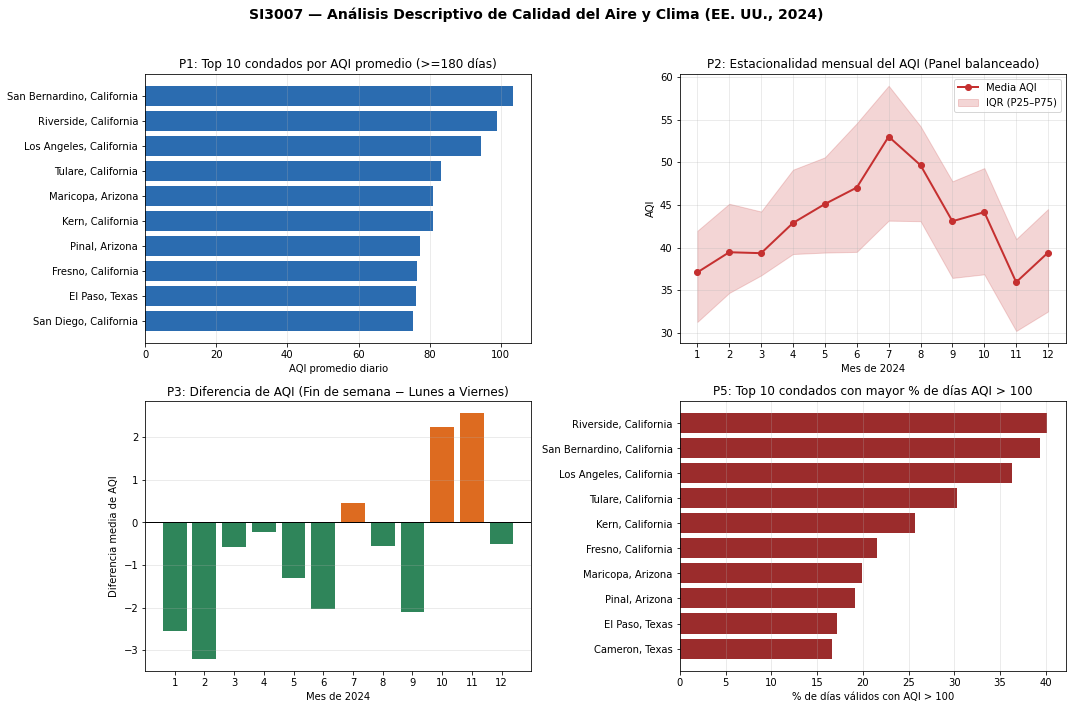

In [15]:
%%local
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt

API_URL = "https://7wbgsfv6wf.execute-api.us-east-1.amazonaws.com"

pdf_p1 = pd.read_json(f"{API_URL}/datasets/p1_counties").head(10)
pdf_p2 = pd.read_json(f"{API_URL}/datasets/p2_monthly").sort_values("month")
pdf_p3 = pd.read_json(f"{API_URL}/datasets/p3_weekday").sort_values("month")
pdf_p5 = pd.read_json(f"{API_URL}/datasets/p5_exceedances").head(10)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("SI3007 — Análisis Descriptivo de Calidad del Aire y Clima (EE. UU., 2024)", fontsize=14, fontweight="bold")

# 1. P1: Top 10 condados por AQI promedio
t1 = pdf_p1.iloc[::-1]
axes[0, 0].barh(t1["county_name"] + ", " + t1["state_name"], t1["avg_aqi"], color="#2b6cb0")
axes[0, 0].set_title("P1: Top 10 condados por AQI promedio (>=180 días)")
axes[0, 0].set_xlabel("AQI promedio diario")
axes[0, 0].grid(axis="x", alpha=0.3)

# 2. P2: Estacionalidad mensual con banda IQR
axes[0, 1].plot(pdf_p2["month"], pdf_p2["mean_aqi"], marker="o", color="#c53030", linewidth=2, label="Media AQI")
axes[0, 1].fill_between(pdf_p2["month"], pdf_p2["p25_aqi"], pdf_p2["p75_aqi"], color="#c53030", alpha=0.2, label="IQR (P25–P75)")
axes[0, 1].set_title("P2: Estacionalidad mensual del AQI (Panel balanceado)")
axes[0, 1].set_xticks(range(1, 13))
axes[0, 1].set_xlabel("Mes de 2024")
axes[0, 1].set_ylabel("AQI")
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# 3. P3: Diferencia fin de semana - laboral
colors_p3 = ["#2f855a" if v < 0 else "#dd6b20" for v in pdf_p3["mean_diff_aqi"]]
axes[1, 0].bar(pdf_p3["month"], pdf_p3["mean_diff_aqi"], color=colors_p3)
axes[1, 0].axhline(0, color="black", linewidth=1)
axes[1, 0].set_title("P3: Diferencia de AQI (Fin de semana − Lunes a Viernes)")
axes[1, 0].set_xticks(range(1, 13))
axes[1, 0].set_xlabel("Mes de 2024")
axes[1, 0].set_ylabel("Diferencia media de AQI")
axes[1, 0].grid(axis="y", alpha=0.3)

# 4. P5: Top 10 condados con mayor % de días AQI > 100
t5 = pdf_p5.iloc[::-1]
axes[1, 1].barh(t5["county_name"] + ", " + t5["state_name"], t5["pct_days_aqi_gt_100"], color="#9b2c2c")
axes[1, 1].set_title("P5: Top 10 condados con mayor % de días AQI > 100")
axes[1, 1].set_xlabel("% de días válidos con AQI > 100")
axes[1, 1].grid(axis="x", alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()